In [1]:

!git clone https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour.git
%cd ErdaKryeziu_TrappistTour
!python --version
!pip install -q pygmo pykep pymoo
!pip show pygmo pykep pymoo | grep -E "Name|Version"

Cloning into 'ErdaKryeziu_TrappistTour'...
remote: Enumerating objects: 15, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 15 (delta 2), reused 12 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (15/15), 4.58 KiB | 781.00 KiB/s, done.
Resolving deltas: 100% (2/2), done.
/kaggle/working/ErdaKryeziu_TrappistTour
Python 3.13.18
Name: pygmo
Version: 2.20.0
Name: pykep
Version: 3.1.0
Name: pymoo
Version: 0.6.2


In [2]:
import pygmo as pg
import pykep as pk
print("importet OK")

# test i vogël: NSGA-II në një problem multi-objektiv standard (ZDT1)
prob = pg.problem(pg.zdt(1))
algo = pg.algorithm(pg.nsga2(gen=50))
pop = pg.population(prob, 52)
pop = algo.evolve(pop)
print(pop.get_f()[:3])


importet OK
[[  3.53492852e-05   1.83032248e+00]
 [  9.99465576e-01   4.66420233e-01]
 [  4.17912165e-01   9.66262890e-01]]


In [4]:
%%bash
cd /kaggle/working/ErdaKryeziu_TrappistTour
ls src scripts


scripts:
setup_kaggle.sh
smoke_test.py

src:
__init__.py
trappist_udp.py


In [5]:
%cd /kaggle/working/ErdaKryeziu_TrappistTour
!bash scripts/setup_kaggle.sh


/kaggle/working/ErdaKryeziu_TrappistTour
ENV READY


In [6]:
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/smoke_test.py

dim 34 nobj 2 nix 7 nec 1 nic 1
fitness(example): (np.float64(2378.9924055773276), 3469.8267032589047, 0, -635763351.2476971)
== 1 : starting point -> planet_b
Duration: 1501.691924d
DV: 17.394596m/s

== 2 : planet_b -> planet_c ==
Duration: 255.879949d
Fly-by epoch: 8501.691924 mjd2000
Fly-by radius: 1.512021 planetary radii
DSM after 58.915229d
DSM magnitude: 575.025437m/s

== 3 : planet_c -> planet_d ==
Duration: 318.614088d
Fly-by epoch: 8757.571873 mjd2000
Fly-by radius: 8.278276 planetary radii
DSM after 32.707716d
DSM magnitude: 719.437756m/s

== 4 : planet_d -> planet_e ==
Duration: 374.628784d
Fly-by epoch: 9076.185961 mjd2000
Fly-by radius: 4.078586 planetary radii
DSM after 125.896200d
DSM magnitude: 304.454612m/s

== 5 : planet_e -> planet_f ==
Duration: 343.820490d
Fly-by epoch: 9450.814745 mjd2000
Fly-by radius: 19.139852 planetary radii
DSM after 166.235995d
DSM magnitude: 98.388885m/s

== 6 : planet_f -> planet_g ==
Duration: 325.153764d
Fly-by epoch: 9794.635235 mjd200

In [1]:
%cd /kaggle/working
!test -d ErdaKryeziu_TrappistTour && (cd ErdaKryeziu_TrappistTour && git pull) || git clone https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour.git
%cd /kaggle/working/ErdaKryeziu_TrappistTour
!ls src scripts
!test -x /kaggle/temp/mm/bin/micromamba && echo "MJEDISI EKZISTON" || bash scripts/setup_kaggle.sh

/kaggle/working
Cloning into 'ErdaKryeziu_TrappistTour'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 37 (delta 9), reused 30 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 15.05 KiB | 3.01 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/kaggle/working/ErdaKryeziu_TrappistTour
scripts:
day2_sampling.py  setup_kaggle.sh  smoke_test.py

src:
__init__.py  problem.py  trappist_udp.py
ENV READY


In [2]:
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/day2_sampling.py 1000

Dimensionet: 34 (te vazhdueshme: 27, te plota: 7)
Po vleresoj 1000 zgjidhje te rastesishme (seed=42)...
Koha: 0.56 s (0.556 ms per vleresim)

=== PERMBLEDHJE ===
status 'ok'      : 1000 / 1000
death penalty    : 0
perjashtime      : 0
te vlefshme (ineq <= 0): 46 / 1000
te vlefshme dhe brenda kutise (DV<2500, T<4000): 0
DV (status ok): min=18196.3  mediana=852857.2
T  (status ok): min=2708.0  mediana=7037.3  max=11448.6
DV me i miri nder te vlefshmet: 18196.3 m/s (T=8853.9 d)

Grafiku u ruajt: /kaggle/working/ErdaKryeziu_TrappistTour/scripts/../results/day2_random_sampling.png


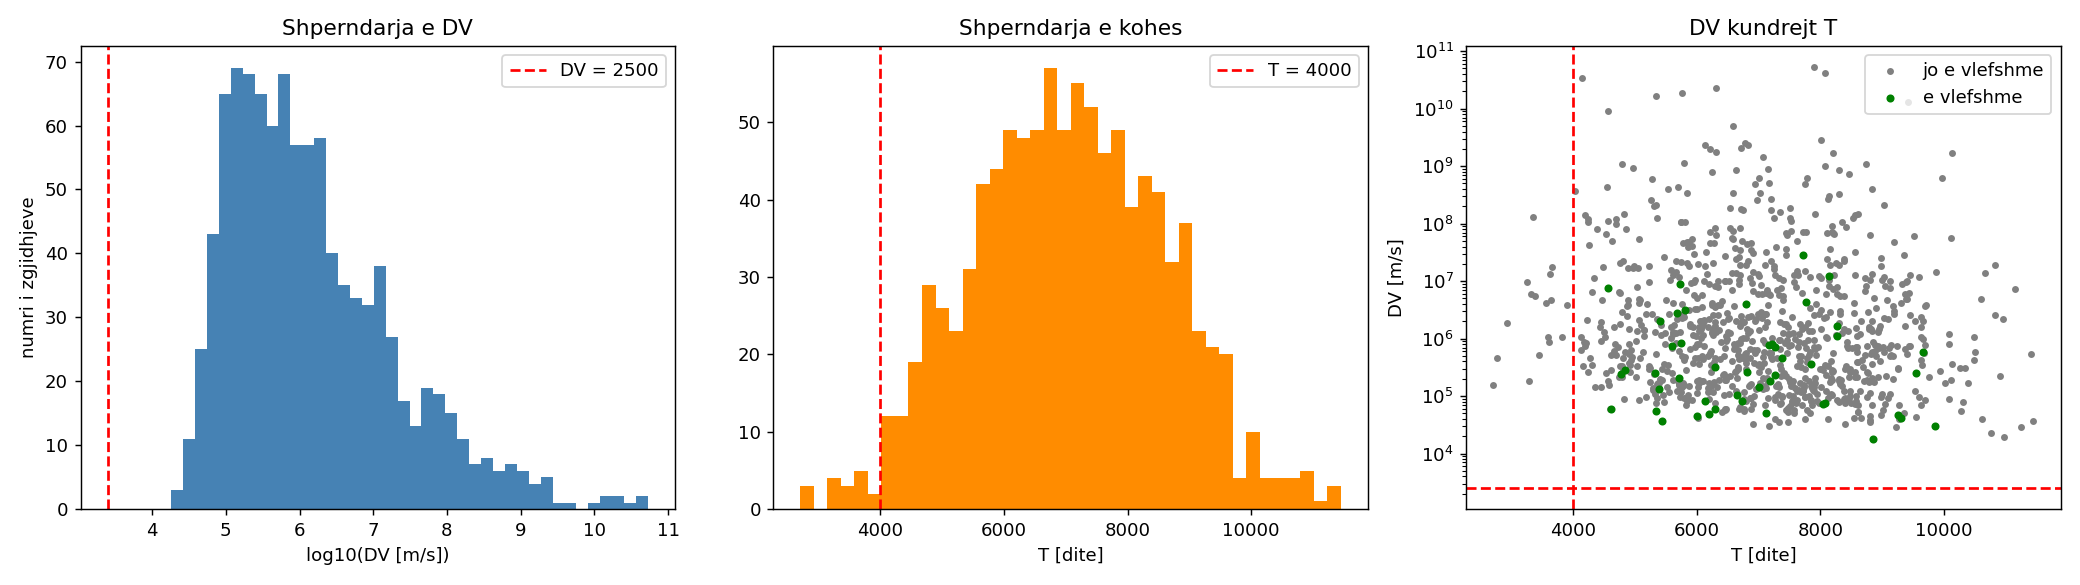

In [4]:
from IPython.display import Image
Image("/kaggle/working/ErdaKryeziu_TrappistTour/results/day2_random_sampling.png")

In [5]:
from IPython.display import FileLink, display
display(FileLink("results/day2_random_sampling.png"))
display(FileLink("results/random_samples.csv"))


/kaggle/working/ErdaKryeziu_TrappistTour/results/day2_random_sampling.png

/kaggle/working/ErdaKryeziu_TrappistTour/results/random_samples.csv


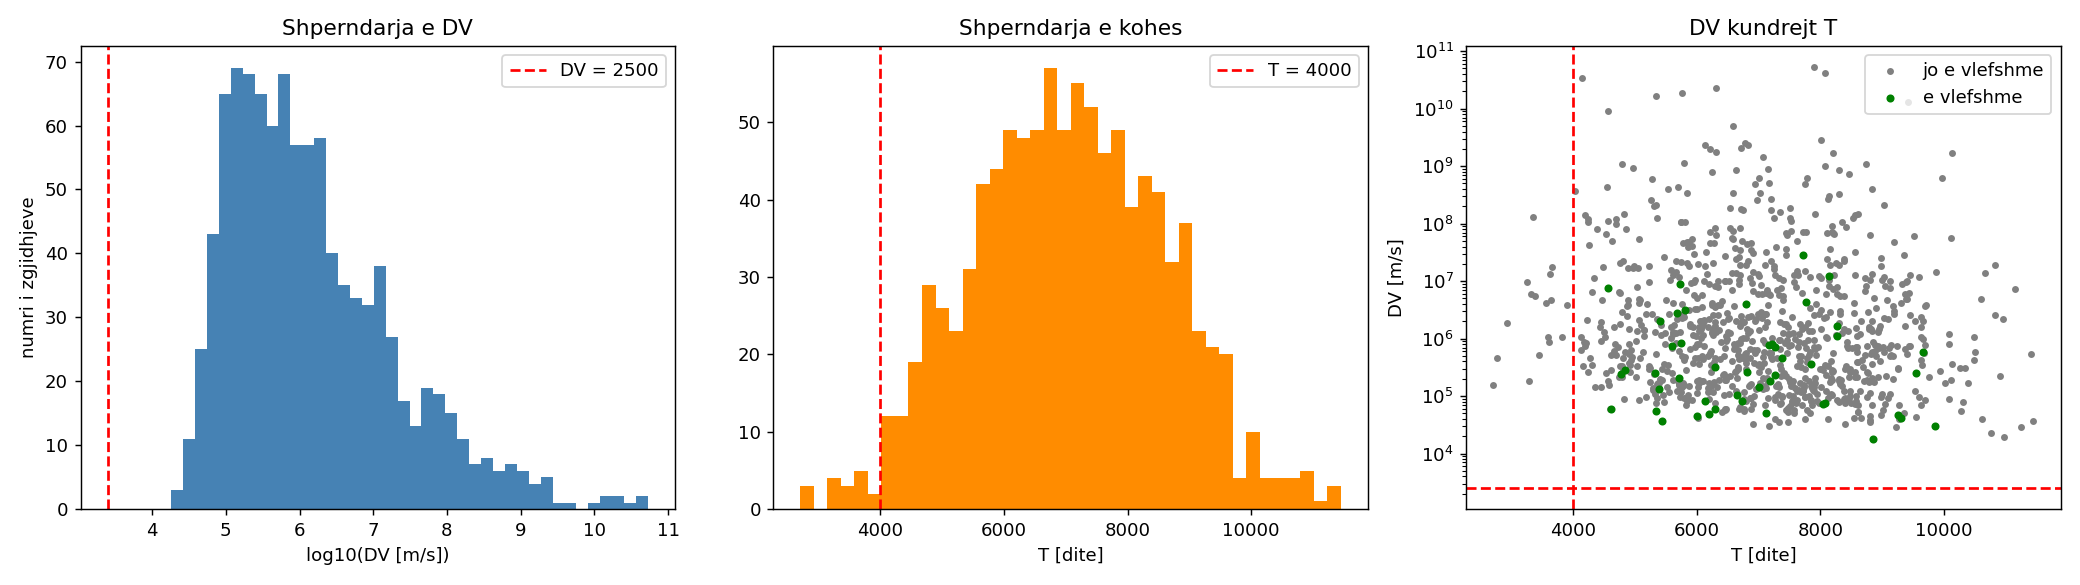

In [6]:
import base64
from IPython.display import HTML, display

def shkarko(path, emri, mime):
    b = base64.b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<a download="{emri}" href="data:{mime};base64,{b}" '
                 f'style="font-size:18px">⬇ Shkarko {emri}</a>'))

shkarko("/kaggle/working/ErdaKryeziu_TrappistTour/results/day2_random_sampling.png", "day2_random_sampling.png", "image/png")
shkarko("/kaggle/working/ErdaKryeziu_TrappistTour/results/random_samples.csv", "random_samples.csv", "text/csv")

In [1]:
%cd /kaggle/working
!test -d ErdaKryeziu_TrappistTour && (cd ErdaKryeziu_TrappistTour && git pull) || git clone https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour.git
%cd /kaggle/working/ErdaKryeziu_TrappistTour
!ls src scripts
!test -x /kaggle/temp/mm/bin/micromamba && echo "MJEDISI EKZISTON" || bash scripts/setup_kaggle.sh

/kaggle/working
Cloning into 'ErdaKryeziu_TrappistTour'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 51 (delta 15), reused 40 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 126.39 KiB | 4.68 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/kaggle/working/ErdaKryeziu_TrappistTour
scripts:
day2_sampling.py  day3_nsga2.py  setup_kaggle.sh  smoke_test.py

src:
__init__.py  moo.py  problem.py  trappist_udp.py
ENV READY


In [2]:
%cd /kaggle/working/ErdaKryeziu_TrappistTour
!git pull
!test -x /kaggle/temp/mm/bin/micromamba && echo "MJEDISI EKZISTON" || bash scripts/setup_kaggle.sh
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/day3_nsga2.py 50 100 42

/kaggle/working/ErdaKryeziu_TrappistTour
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 6 (delta 5), reused 6 (delta 5), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.75 KiB | 897.00 KiB/s, done.
From https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour
   f4b12cd..0f5d4b1  main       -> origin/main
Updating f4b12cd..0f5d4b1
Fast-forward
 scripts/day3_nsga2.py | 144 ++++++++++++++++++++++++++++----------------------
 src/moo.py            |  13 +++++
 2 files changed, 95 insertions(+), 62 deletions(-)
MJEDISI EKZISTON
Kontroll: zgjidhja shembull e ESA-s DV=2379.0, T=3469.8 -> HV=64155
          (duhet: (2500-2379.0) x (4000-3469.8) = 64155)

NSGA-II: pop=100, gen=50, seed=42, kufiri i kohes: pa kufi
gen      50 | vleresime      5100 | HV            0 | DV me i mire      19546.1 | ne kuti     0 | pop e vlefshme 100.0% |      1.6 s

=== PERMBLEDHJE NSGA-II ===
Gjenerata        

Kontroll: zgjidhja shembull e ESA-s DV=2379.0, T=3469.8 -> HV=64155
          (duhet: (2500-2379.0) x (4000-3469.8) = 64155)

NSGA-II: pop=100, gen=2000, seed=42, kufiri i kohes: pa kufi
gen      50 | vleresime      5100 | HV            0 | DV me i mire      19546.1 | ne kuti     0 | pop e vlefshme 100.0% |      1.6 s
gen     100 | vleresime     10100 | HV            0 | DV me i mire      17277.2 | ne kuti     0 | pop e vlefshme 100.0% |      3.2 s
gen     150 | vleresime     15100 | HV            0 | DV me i mire      13634.5 | ne kuti     0 | pop e vlefshme 100.0% |      4.8 s
gen     200 | vleresime     20100 | HV            0 | DV me i mire      13634.5 | ne kuti     0 | pop e vlefshme 100.0% |      6.4 s
gen     250 | vleresime     25100 | HV            0 | DV me i mire      12840.4 | ne kuti     0 | pop e vlefshme 100.0% |      7.9 s
gen     300 | vleresime     30100 | HV            0 | DV me i mire      10864.1 | ne kuti     0 | pop e vlefshme 100.0% |      9.7 s
gen     350 | v

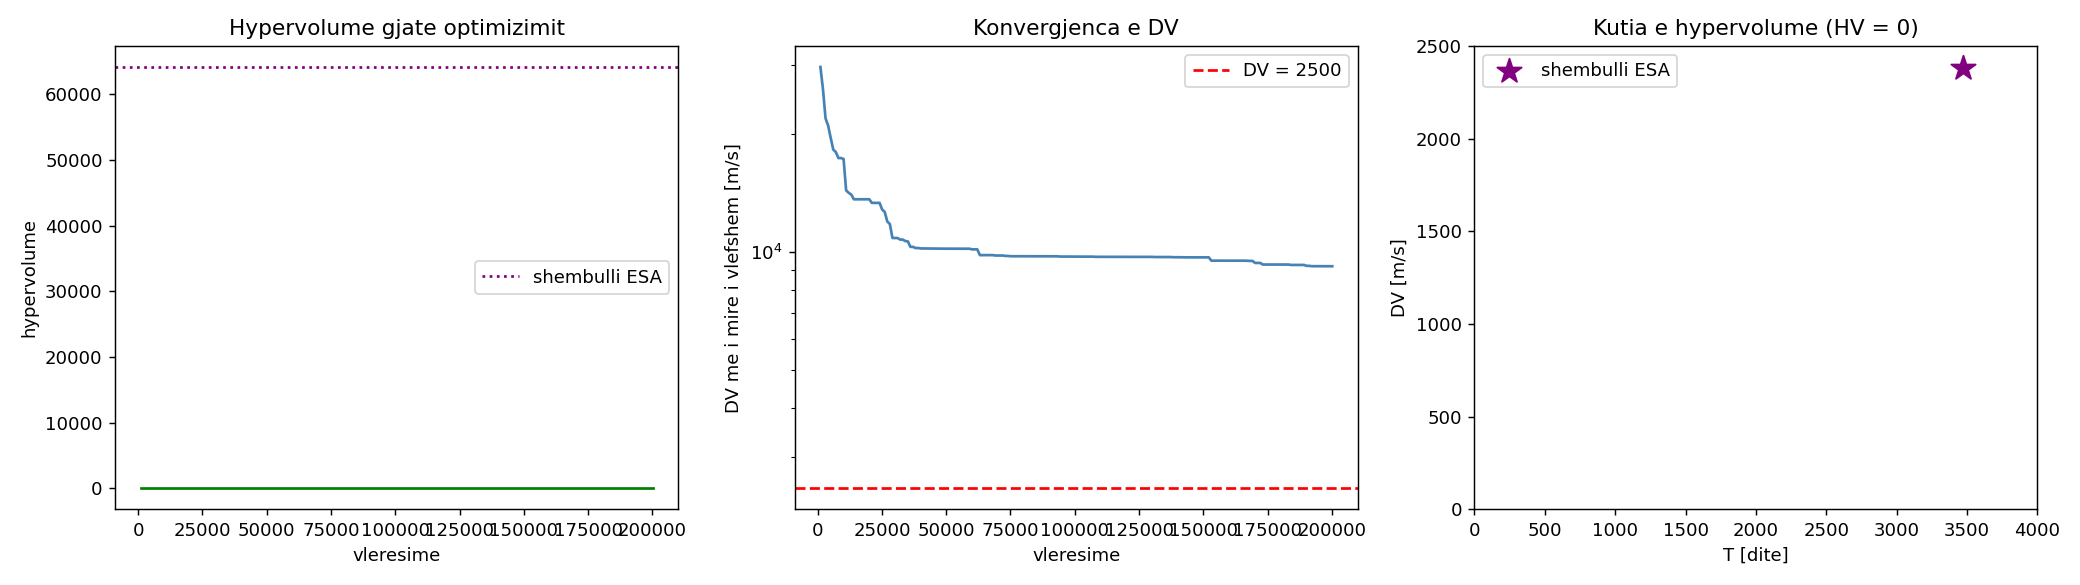

In [3]:
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/day3_nsga2.py 2000 100 42
from IPython.display import Image
Image("results/day3_nsga2_seed42.png")

remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 6 (delta 5), reused 6 (delta 5), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.39 KiB | 713.00 KiB/s, done.
From https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour
   0f5d4b1..cfcfe72  main       -> origin/main
Updating 0f5d4b1..cfcfe72
Fast-forward
 scripts/day3_nsga2.py | 25 ++++++++++++++++---------
 src/moo.py            | 32 +++++++++++++++++++++++++++++---
 2 files changed, 45 insertions(+), 12 deletions(-)
Kontroll: zgjidhja shembull e ESA-s DV=2379.0, T=3469.8 -> HV=64155
          (duhet: (2500-2379.0) x (4000-3469.8) = 64155)

NSGA-II: pop=100, gen=2000, seed=42, kufijte: tight, kufiri i kohes: pa kufi
gen      50 | vleresime      5100 | HV            0 | DV me i mire      31680.1 | ne kuti     0 | pop e vlefshme 100.0% |      1.6 s
gen     100 | vleresime     10100 | HV            0 | DV me i mire      27496.6 | ne k

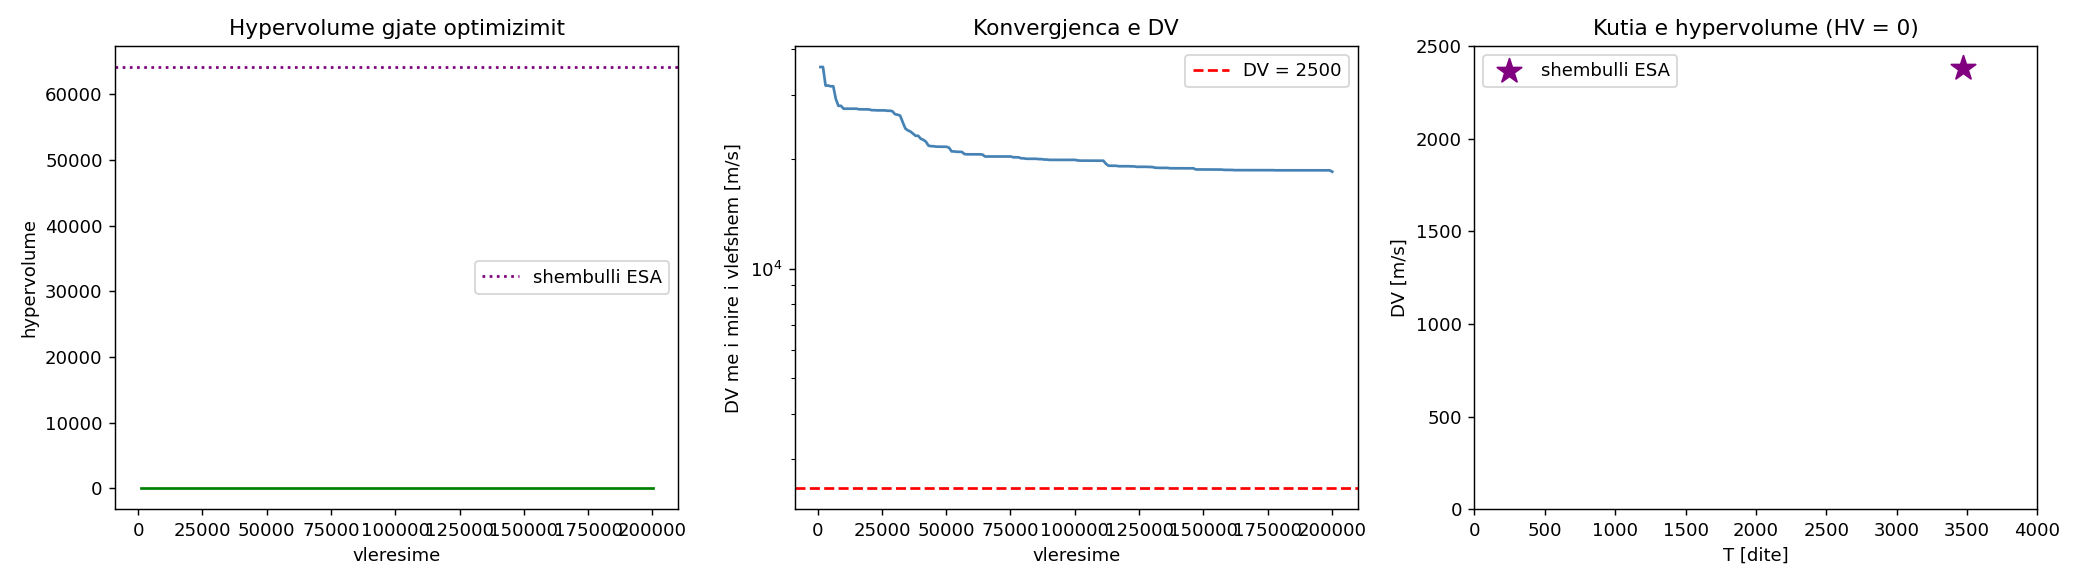

In [4]:
!git pull
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/day3_nsga2.py 2000 100 42 0 tight
from IPython.display import Image
Image("results/day3_nsga2_tight_seed42.png")

remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 6 (delta 5), reused 6 (delta 5), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.47 KiB | 751.00 KiB/s, done.
From https://github.com/ErdaKryeziu/ErdaKryeziu_TrappistTour
   cfcfe72..286bfc0  main       -> origin/main
Updating cfcfe72..286bfc0
Fast-forward
 scripts/day3_nsga2.py | 17 ++++++++++++-----
 src/moo.py            | 32 ++++++++++++++++++++++++++++++++
 2 files changed, 44 insertions(+), 5 deletions(-)
Kontroll: zgjidhja shembull e ESA-s DV=2379.0, T=3469.8 -> HV=64155
          (duhet: (2500-2379.0) x (4000-3469.8) = 64155)

NSGA-II: pop=100, gen=2000, seed=42, kufijte: warm, kufiri i kohes: pa kufi
Popullata fillestare: 100 zgjidhje, HV fillestar = 64155
gen      50 | vleresime      5100 | HV       318015 | DV me i mire       1912.3 | ne kuti   366 | pop e vlefshme 100.0% |      1.5 s
gen     100 | vleresime     10100 | HV 

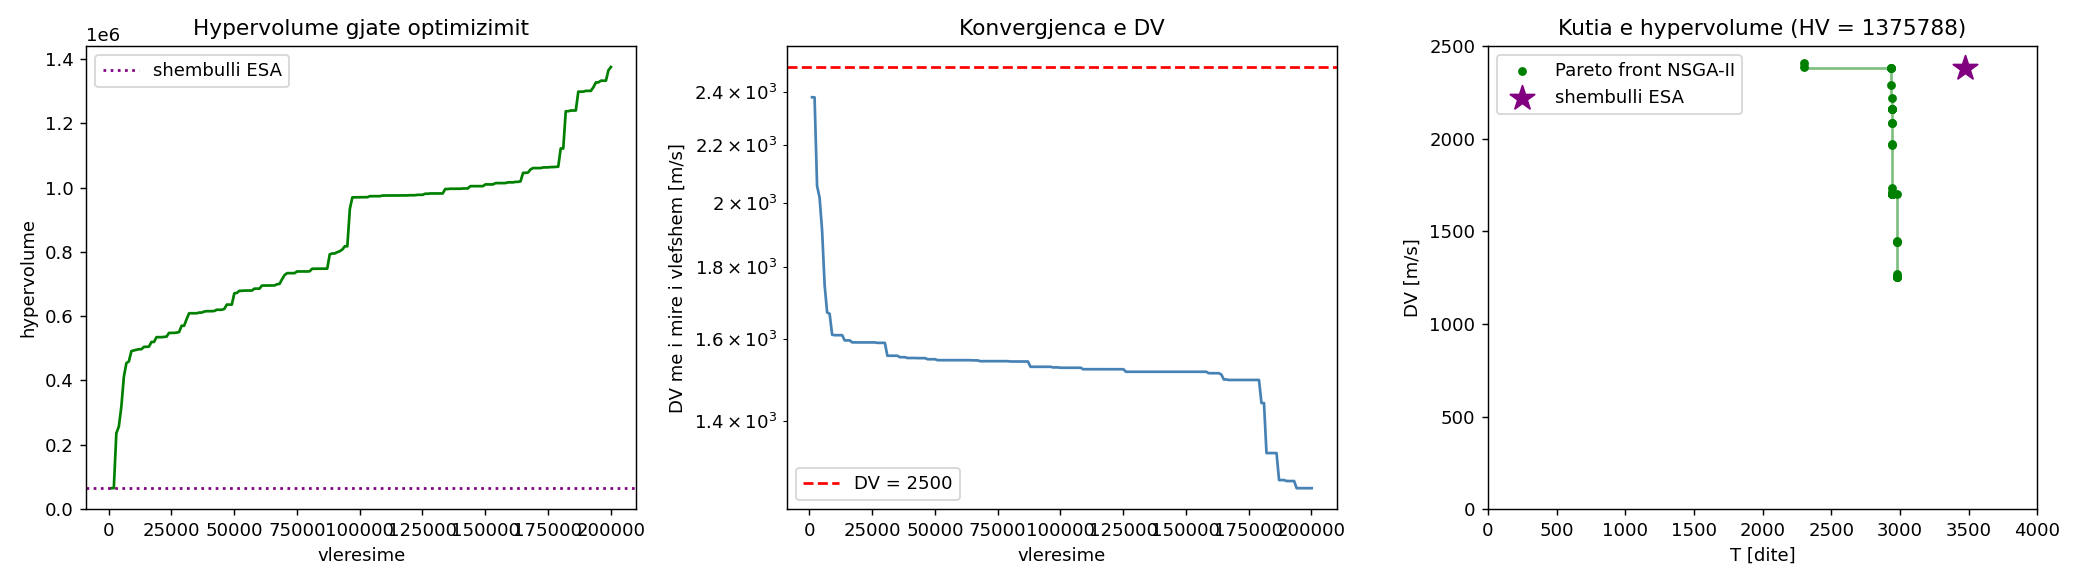

In [5]:
!git pull
!MAMBA_ROOT_PREFIX=/kaggle/temp/mroot /kaggle/temp/mm/bin/micromamba run -n old python scripts/day3_nsga2.py 2000 100 42 0 warm
from IPython.display import Image
Image("results/day3_nsga2_warm_seed42.png")